In [ ]:
# Given a new microbe, predict what it might consume or secrete based on its taxonomy

# Given a media composition and a list of microbes, predict which microbes will eat which compounds

# move the model and parquet files to repo instead of scratch so they can be commited

# replace pkl with json and numPy files (see prompt. search for npz)

In [2]:
import wom
	# Bacteria; Pseudomonadota; Alphaproteobacteria; Candidatus Pelagibacterales; Candidatus Pelagibacteraceae; Candidatus Pelagibacter; Candidatus Pelagibacter communis
# The provided text describes the taxonomic classification of a group of abundant marine bacteria, 
# belonging to the genus Candidatus Pelagibacter within the SAR11 clade 
# (family Pelagibacteraceae, order Pelagibacterales, class Alphaproteobacteria, phylum Pseudomonadota), specifically
# Query for a genus we haven't measured
# result = wom.predict_consumption_novel(
    # taxonomy={"genus": "Pseudomonas", "family": "Pseudomonadaceae"}
# )
# result = wom.predict_consumption_novel(
#     taxonomy={ "family": "Pelagibacteraceae"}
# )
# print(result)

# Get explanation of the prediction
context = wom.get_phylogenetic_context(
    taxonomy={"genus": "Gordonia"},
    model_type="consumed"
)
print(f"Based on {len(context['neighbors'])} neighbors")
print(f"Confidence: {context['confidence']:.2f}")
for n in context["neighbors"][:3]:
    print(f"  {n['taxon']} (distance={n['distance']}, weight={n['weight']:.2f})")

Based on 2 neighbors
Confidence: 0.33
  Rhodococcus (distance=1, weight=0.80)
  Microbacterium (distance=3, weight=0.20)


In [ ]:
import wom

wom.predict_consumption_novel(taxonomy={"genus": "Pseudomonas", "family": "Pseudomonadaceae"})



,chebi_id,chebi_name,score,based_on
0,16235,GUANINE,8.778588,genus: Pseudomonas
1,16708,ADENINE,7.137001,genus: Pseudomonas
2,18050,GLUTAMINE,7.009935,genus: Pseudomonas
3,17115,SERINE,6.921579,genus: Pseudomonas
4,17053,ASPARTIC ACID,6.827742,genus: Pseudomonas
5,17368,HYPOXANTHINE,6.800319,genus: Pseudomonas
6,17196,ASPARAGINE,6.287480,genus: Pseudomonas
7,15428,Glycine,6.129968,genus: Pseudomonas
8,18019,lysine,5.869923,genus: Pseudomonas
9,6650,Malic acid,5.686333,genus: Pseudomonas


In [13]:
import wom
match = wom.resolve_taxon("variovorax")
print(match)
match = wom.resolve_metabolite("sucrose")
print(match)

{'name': 'Variovorax', 'rank': 'genus', 'score': 100.0}
{'chebi_id': 17992, 'name': 'Sucrose', 'score': 100.0}


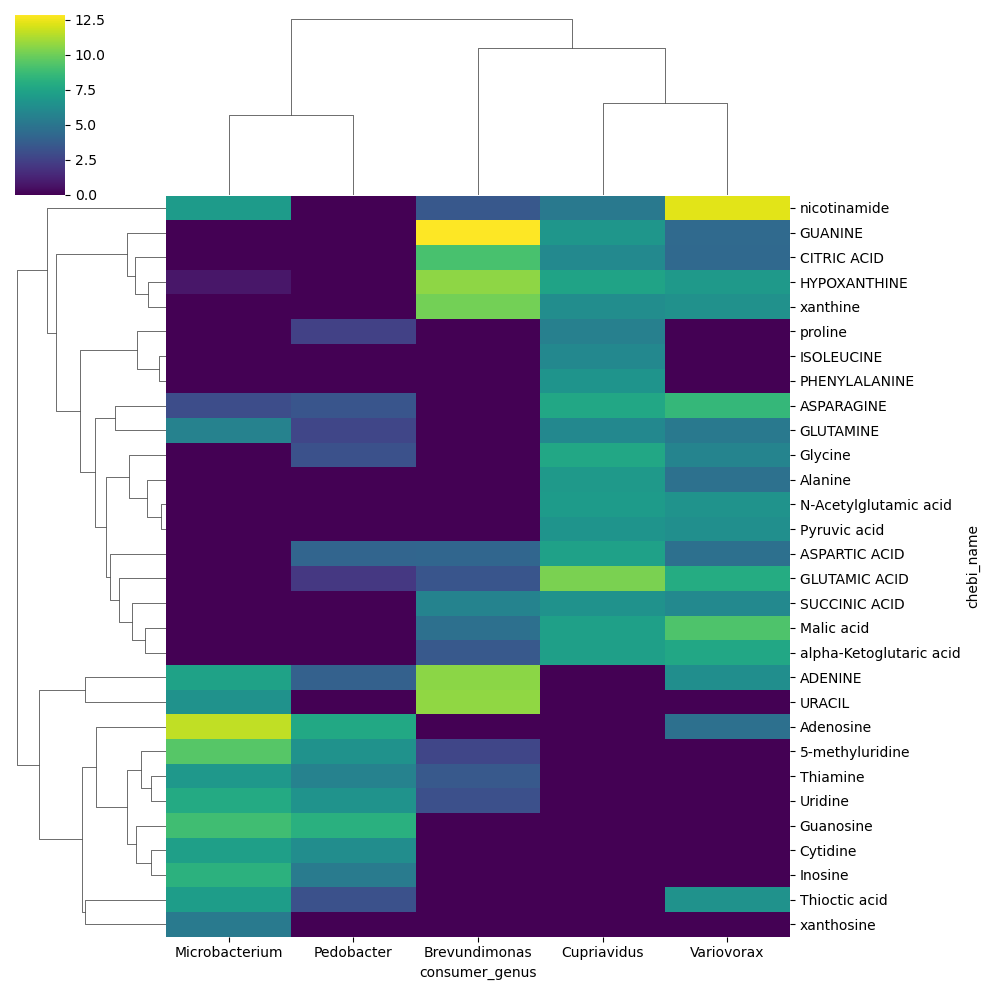

In [7]:
genera = ['Variovorax','Cupriavidus','Microbacterium','Brevundimonas','Pedobacter']
data = []
for genus in genera:
    temp = wom.consumed_by(genus=genus)
    temp['consumer_genus'] = genus
    data.append(temp)
import pandas as pd
df = pd.concat(data)
df = pd.pivot_table(df, index='chebi_name', columns='consumer_genus', values='mean_score', fill_value=0)
idx = df.max(axis=1)>5
df = df.loc[idx]
import seaborn as sns
import matplotlib.pyplot as plt
sns.clustermap(df, cmap='viridis')
plt.show()

In [12]:
out = wom.secretes(chebi_id=15354)
out

,organism_id,score,genus,family
0,FW507-4G11,0.048704,Cupriavidus,Burkholderiaceae
1,GW822-FHT05C07,0.037389,Zoogloea,Rhodocyclaceae
2,GW460-11-11-14-LB1,0.034676,Hydrogenophaga,Comamonadaceae
3,GW101-3H06,0.031258,Pseudomonas,Pseudomonadaceae
4,GW460-E12,0.030530,Pseudomonas,Pseudomonadaceae
5,MPR-LB4,0.027240,Azospira,Rhodocyclaceae
6,MLSD5-FHT05B12,0.026644,Afipia,Xanthobacteraceae
7,FW507-F1,0.026481,Pseudogulbenkiania,Chromobacteriaceae
8,GW460-11-11-14-LB5,0.022053,Pedobacter,Sphingobacteriaceae
9,GW456-E5,0.020699,Comamonas,Burkholderiaceae


In [14]:
out = wom.consumes(chebi_id=17992)
out

,organism_id,score,genus,family
0,FW305-C-30-35,7.607486,Novosphingobium,Sphingomonadaceae
1,GW458-12-2-14-TSB2,6.728559,Arcicella,Spirosomaceae
2,GW456-11-11-14-LB4,6.319359,Flavobacterium,Flavobacteriaceae
3,FW306-1B-G06A,4.465430,MA-N2,Micrococcaceae
4,FW305-C-30-S16,3.517472,Caulobacter,Caulobacteraceae
5,GW456-11-11-14-TSB4,3.345709,Pedobacter,Sphingobacteriaceae
6,FW306-02-B,3.215751,Paraburkholderia,Burkholderiaceae
7,EB106-06-01-XG185,2.927515,None,Bacillaceae
8,FW306-07-L,2.740957,Mucilaginibacter,Sphingobacteriaceae
9,FW305-3-2-15-C-LB1,2.043120,Pseudomonas,Pseudomonadaceae


In [4]:
import wom

# Taxonomy-level queries
out = wom.consumed_by(genus="Serratia", top_k=20)
print(out.head(3))
out_secretes = wom.secreted_by(family="Rhodanobacteraceae", top_k=15)
print(out_secretes.head(3))

# Organism-level queries  
out = wom.predict_consumption("CPT56D-587-MTF", top_k=10)
print(out)
out = wom.similar_organisms("CPT56D-587-MTF")
print(out)
# Metabolite-level queries
out = wom.consumes(chebi_id=18050)  # glucose
print(out)
out = wom.secretes(chebi_id=28358)
print(out)
wom.cross_feeding_potential("CPT56D-587-MTF", "FW104-10B1")

# KG integration
# wom.paths_between("CHEBI:15903", "NCBITaxon:123456")

# Community queries
# wom.community_profile(["isolate1", "isolate2", "isolate3"])
# wom.niche_overlap("isolateA", "isolateB")


   chebi_id  chebi_name  mean_score  n_isolates
0     17196  ASPARAGINE    9.690809           1
1     17115      SERINE    8.625442           1
2     15428     Glycine    8.050776           1
   chebi_id           chebi_name  mean_score  n_isolates
0     15940       Nicotinic acid    6.211069           8
1     30753  4-AMINOBENZOIC ACID    0.026603           8
2      7916     Pantothenic acid   -0.366181           8
   chebi_id           chebi_name      score
0     16750            Guanosine  14.006931
1     16335            Adenosine  12.790482
2     17596              Inosine  11.107393
3     17562             Cytidine  10.091732
4     16704              Uridine   9.508530
5     18385             Thiamine   8.360345
6     45996      5-methyluridine   8.200827
7     28009  N-acetylglucosamine   6.470850
8      4167              glucose   6.300653
9     18050            GLUTAMINE   5.653797
           organism_id  similarity           genus               family
0  GW456-11-11-14-TSB4  

{'a_feeds_b': [{'chebi_id': 18050, 'chebi_name': 'GLUTAMINE'},
  {'chebi_id': 16015, 'chebi_name': 'GLUTAMIC ACID'},
  {'chebi_id': 17562, 'chebi_name': 'Cytidine'},
  {'chebi_id': 17821, 'chebi_name': 'thymine'},
  {'chebi_id': 17053, 'chebi_name': 'ASPARTIC ACID'},
  {'chebi_id': 16414, 'chebi_name': 'VALINE'},
  {'chebi_id': 17191, 'chebi_name': 'ISOLEUCINE'},
  {'chebi_id': 45996, 'chebi_name': '5-methyluridine'},
  {'chebi_id': 17196, 'chebi_name': 'ASPARAGINE'},
  {'chebi_id': 32816, 'chebi_name': 'Pyruvic acid'}],
 'b_feeds_a': [{'chebi_id': 18050, 'chebi_name': 'GLUTAMINE'},
  {'chebi_id': 16899, 'chebi_name': 'mannitol'},
  {'chebi_id': 17154, 'chebi_name': 'nicotinamide'},
  {'chebi_id': 17053, 'chebi_name': 'ASPARTIC ACID'},
  {'chebi_id': 17821, 'chebi_name': 'thymine'},
  {'chebi_id': 17568, 'chebi_name': 'URACIL'},
  {'chebi_id': 17196, 'chebi_name': 'ASPARAGINE'},
  {'chebi_id': 18222, 'chebi_name': 'Xylose'},
  {'chebi_id': 32816, 'chebi_name': 'Pyruvic acid'},
  {'cheb

In [8]:
import pandas as pd
f = '/pscratch/sd/b/bpb/wom_data_cache/cache/exometabolite.parquet'
df = pd.read_parquet(f)
df.head()

,organism_id,timepoint_h,compound_name,assertion_value,source_file,chebi_id,chebi_name,compound_match_type,chebi_id_formatted,assertion,kingdom,class,order,family,genus,species
0,CPT56D-587-MTF,24.0,5-methyluridine,-5,Biggs_isolates.tsv,45996,5-methyluridine,exact,CHEBI:45996,consumed,Bacteria,Bacilli,Bacillales,Bacillaceae,None,NaN
1,EB106-03-01-XG64,24.0,5-methyluridine,-5,Biggs_isolates.tsv,45996,5-methyluridine,exact,CHEBI:45996,consumed,Bacteria,Actinomycetia,Actinomycetales,Microbacteriaceae,Microbacterium,NaN
2,EB106-05-01-XG147,24.0,5-methyluridine,1,Biggs_isolates.tsv,45996,5-methyluridine,exact,CHEBI:45996,neutral,Bacteria,Gammaproteobacteria,Burkholderiales,Burkholderiaceae,Cupriavidus,NaN
3,EB106-06-01-XG185,24.0,5-methyluridine,-5,Biggs_isolates.tsv,45996,5-methyluridine,exact,CHEBI:45996,consumed,Bacteria,Bacilli,Bacillales,Bacillaceae,None,NaN
4,EB106-07-01-XG149,24.0,5-methyluridine,-5,Biggs_isolates.tsv,45996,5-methyluridine,exact,CHEBI:45996,consumed,Bacteria,Bacilli,Bacillales,Bacillaceae,None,NaN


In [8]:
import pandas as pd
kgm_nodes_filename = '/pscratch/sd/b/bpb/wom_data_cache/raw/kg-microbe-core/merged-kg/merged-kg_nodes.tsv'
kgm_edges_filename = '/pscratch/sd/b/bpb/wom_data_cache/raw/kg-microbe-core/merged-kg/merged-kg_edges.tsv'
mg_nodes_filename = '/pscratch/sd/b/bpb/wom_data_cache/raw/MetagenomicKG/MetagenomicKG/KG_nodes.tsv'
mg_edges_filename = '/pscratch/sd/b/bpb/wom_data_cache/raw/MetagenomicKG/MetagenomicKG/KG_edges.tsv'

my_files = [kgm_edges_filename, mg_edges_filename, kgm_nodes_filename, mg_nodes_filename]
for f in my_files:
    source = 'kg-microbe' if 'kg-microbe' in f else 'metagenomic-kg'
    data_type = 'edges' if 'edges' in f else 'nodes'
    print(f"Source: {source} | Data type: {data_type}")
    print(f"File: {f}")
    df = pd.read_csv(f, sep='\t', dtype=str,nrows=500000)
    if 'category' in df.columns:
        df.rename(columns={'category':'node_type'}, inplace=True)
    print(f"Columns: {df.columns}")
    print(df.sample(20).to_string(index=False))
    if data_type == 'nodes':
        print(f"Unique node categories: {df['node_type'].nunique()}")
        print(f"Node categories: {df['node_type'].value_counts().to_string()}")
    print("\n")

Source: kg-microbe | Data type: edges
File: /pscratch/sd/b/bpb/wom_data_cache/raw/kg-microbe-core/merged-kg/merged-kg_edges.tsv
Columns: Index(['id', 'subject', 'predicate', 'object', 'relation', 'knowledge_source',
       'meta', 'primary_knowledge_source', 'primary_knowledge_source.1'],
      dtype='object')
                                           id                                  subject             predicate               object        relation knowledge_source meta primary_knowledge_source primary_knowledge_source.1
urn:uuid:50d6238d-de76-45e6-8a8e-80cb663b10f9                         NCBITaxon:598549 biolink:has_phenotype              gc:high      RO:0002200            Graph  NaN          BactoTraits.csv                        NaN
urn:uuid:b779441d-c9ff-4efa-b124-817ffd96c3a4                        assay:API_20E_ARA      biolink:assesses      NCBITaxon:83655    NCIT:C153110            Graph  NaN           bacdive:144612                        NaN
urn:uuid:6276d64a-fea4-47ff-